# <font color='red' size='6'>Inteligência Artificial</font>
### Atividade: Previsão de óbito por COVID-19
<font color='red' size='4'><b>Problema de Negócio</b></font>: Com base nos dados obtidos de (1), o problema de negócio é: prever se uma pessoa pode vir a óbito ou não por COVID-19.

(1) COVID-19 Mexico Patient Health Dataset. (2020, 05 19). Disponível em Kaggle.com: https://www.kaggle.com/riteshahlawat/covid19-mexico-patient-health-dataset . Data da consulta: 15 de março de 2025.

Fonte: YAVUZ, Ü. N. A. L.; DUDAK, Muhammed Nuri. Classification of Covid-19 Dataset with Some Machine Learning Methods. Journal of Amasya University the Institute of Sciences and Technology, v. 1, n. 1, p. 30-37. Disponível em: https://dergipark.org.tr/en/pub/jauist/issue/55760/748667. Data da Consulta: 15 de Marco de 2025.
 
<font color='red' size='4'><b>Etapas: Seleção de Atributos. Aprendizado: Aplicação dos Algoritmos, Avaliação, Geração de Modelos Preditivos, Otimização e Validação</b></font>

Descrição: 
<ol>
    <li><b>Executar a análise exploratória</b>: que consta no notebook no dataset "df_covid_preparados.csv". O dataset " df_covid_preparados.csv " contém 95839 casos de COVID-19 que são formados por 19 atributos e registrados pelo governo mexicano entre 15 de janeiro de 2020 e 3 de maio de 2020 para dados sobre a doença de Covid-19.</li>
<li><b>Realizar a Seleção de Atributos</b>: fazendo uso do método ensemble RandomForestClassifier que estima a importância de cada atributo. Gravar esse dataset contendo esses atributos. Os atributos selecionados e os dados associados devem ser gravados em um novo dataset com o nome "dfcovid_atrib_selec.csv"</li>
<li><b>Dataset de validação</b>: a partir do dataset com os atributos selecionados  anteriormente, "dfcovid_atrib_selec.csv", reserve automaticamente 10 casos antes da seleção e do treinamento, sendo 5 COM ÓBITO e 5 SEM ÓBITO. Esses dados serão utilizados na validação dos testes finais</li>
<li><b>Realizar a geração dos modelos preditivos</b>: com validação cruzada estratificada de 10 folds no desenvolvimento, seleção de atributos dentro de cada fold e teste final reservado, pelos algoritmos KNN, Árvore de Decisão (CART), Regressão Logística, Naive Bayes, Support Vector Machine (SVC), Random Forest e Adaboost, estudados na teoria.</li>
<li><b>Escolher um dos algoritmos para realizar o ajuste dos hiperparâmetros</b>: fazer a otimização do modelo com o "Random Search Parameter Tuning". Nesse ponto, ajustar: "valores_grid = {  DEFINIR AQUI O RANGE DOS HIPERPARÂMETROS A SER FEITA A BUSCA PELOS MELHORRES VALORES - pelo menos 2  }", "modelo =  DEFINIR AQUI O MODELO A SER OTIMIZADO OS HIPERPARÂMETROS ",  "iterations = DEFINIR A QUANTIDADE AQUI  maior ou igual a 200 ", "modelo = COLOQUE AQUI O MODELO COM OS MELHORES HIPERPARÂMETROS SELECIONADOS". A partir dos resultados do item anterior e do ajuste dos hiperparâmetros, reflita sobre os resultados obtidos com o relatório de medidas de performance dos modelos, matriz de confusão e discuta-os (Sugestão: considere as métricas, matriz de confusão de cada modelo e cada classe individualmente). </li>
<li><b>Salvar o modelo após o ajuste dos hiperparãmetros</b>: o modelo deve ser obtido pelo algoritmo utilizado no item anterior, otimização do modelo, com os melhores valores para os seus hiperparâmetros. </li>
<li><b>Realizar a validação</b>: a partir dos 10 dados separados no dataset de validação; verifique os resultados obtidos com o modelo otimizado, monte um quadro com os resultados obtidos para os 10 dados de validação; e discuta os resultados obtidos com a validação (compare com as métricas e matriz de confusão, indique limitações e vantagens). Por exemplo, apresente os aspectos positivos e limitações do modelo, tendo por base o relatório de métricas/matriz de confusão do modelo otimizado e os resultados obtidos com os 10 dados do dataset de validação.</li>
</ol>

#### Marcar com um X a turma a qual o grupo pertence.</br>

<b>Turma: ( &nbsp;&nbsp;&nbsp;&nbsp; )   7G</br> Turma: ( X ) 7N </b><p>
<table width="300" border="2">
    <tr>
        <td><b>Nome do Aluno</b> </td>
        <td><b>RA</b></td>
     </tr>  
   <tr>
       <td>Isabelle Franco </td>
       <td>10425395</td>
   </tr>
   <tr>
       <td>Gustavo Rodrigues</td>
       <td>10403091</td>
   </tr>
   <tr>
       <td>Lorenzo Tadeo</td>
       <td>10420067</td>
   </tr>
   <tr>
       <td>Pedro Henrique</td>
       <td>10388298</td>
   </tr>
</table>

**Atualização CV10:** a seleção e a padronização são internas aos folds; a reserva de dez casos é automática e independente. O ajuste apresenta AdaBoost como exemplo configurável com 200 iterações, e utiliza diretamente os melhores parâmetros encontrados.


In [1]:
# Imports
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
# ignora os warnings 
import warnings
warnings.filterwarnings("ignore")
# Por se tratar de um conjunto de gráficos menores, pode ser mais interessante gerar os gráficos em janela separada
%matplotlib inline

# Análise Exploratória: Síntese

In [2]:
# Leitura do arquivo CSV com separador "," e codificação UTF-8
# COVID-19 Mexico Patient Health Dataset. (2020, 05 19). Retrieved 
# from Kaggle.com: https://www.kaggle.com/riteshahlawat/covid19-mexico-patient-health-dataset
df_covid = pd.read_csv('df_covid_preparados.csv', sep = ',', encoding = 'UTF-8')

In [3]:
# Mostra dois registros do arquivo
df_covid.head(2)

,sexo,tipo_paciente,intubado,pneumonia,idade,gravidez,diabetes,copd,asma,imunossupressao,hipertensao,outras_doencas,cardiovascular,obesidade,irc,fumante,outro_caso,teste_covid,icu,obito
0,2,1,97,2,42,97,2,2,1,2,2,2,2,2,2,2,99,1,97,0
1,1,1,97,2,51,2,2,2,2,2,2,2,2,2,2,2,99,1,97,0


In [4]:
# apresenta os tipas de dados das colunas
df_covid.dtypes

sexo               int64
tipo_paciente      int64
intubado           int64
pneumonia          int64
idade              int64
gravidez           int64
diabetes           int64
copd               int64
asma               int64
imunossupressao    int64
hipertensao        int64
outras_doencas     int64
cardiovascular     int64
obesidade          int64
irc                int64
fumante            int64
outro_caso         int64
teste_covid        int64
icu                int64
obito              int64
dtype: object

In [5]:
# Mostra o shape do dataset
df_covid.shape

(95839, 20)

In [6]:
## Mostra a frequência absoluta de  registros do atributo sexo (intervalo: [1,2]), onde:
# 1- Mulher, 2- homem  
df_covid.groupby("sexo").size()

sexo
1    47119
2    48720
dtype: int64

In [7]:
# Mostra a frequência absoluta de  registros do atributo tipo_paciente (intervalo: [1,2]), onde:
# Tipo 1, Tipo 2 
df_covid.groupby("tipo_paciente").size()

tipo_paciente
1    70268
2    25571
dtype: int64

In [8]:
# Mostra a frequência absoluta  de  registros do atributo intubado (intervalo: [1,99]), onde: 
# 1 = Sim, 2 = Não, 98/97: Não se aplica, 99: Não disponível. 
df_covid.groupby("intubado").size()

intubado
1      1934
2     23613
97    70268
99       24
dtype: int64

In [9]:
# Mostra a frequência absoluta  de  registros do atributo pneumonia (intervalo: [1,99]), onde: 
# 1 = Sim, 2 = Não, 98/97: Não se aplica, 99: Não disponível. 
df_covid.groupby("pneumonia").size()

pneumonia
1     17628
2     78203
99        8
dtype: int64

<Axes: >

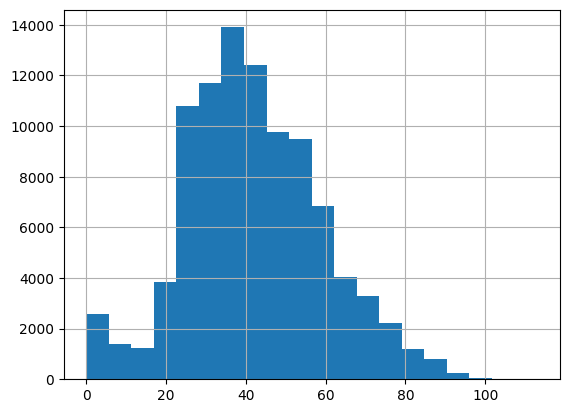

In [10]:
# Apresenta o histograma do atributo idade. Observe a distribuição e os picos.
# Considere bins como sendo o número de barras
df_covid.idade.hist(bins=20)

In [11]:
# Mostra a frequência absoluta de  registros do atributo gravidez (intervalo: [1,98]), onde: 
# 1 = Sim, 2 = Não, 98/97: Não se aplica. 
df_covid.groupby("gravidez").size()

gravidez
1       978
2     45909
97    48720
98      232
dtype: int64

In [12]:
# Mostra a frequência absoluta de  registros do atributo diabetes (intervalo: [1,98]), onde: 
# 1 = Sim, 2 = Não, 98/97: Não se aplica. 
df_covid.groupby("diabetes").size()

diabetes
1     12878
2     82544
98      417
dtype: int64

In [13]:
# Mostra a frequência absoluta de  registros do atributo copd (intervalo: [1,98]), onde: 
# 1 = Sim, 2 = Não, 98/97: Não se aplica. 
# copd = doença pulmonar obstrutiva crônica 
df_covid.groupby("copd").size()

copd
1      2462
2     92973
98      404
dtype: int64

In [14]:
# Mostra a frequência absoluta de  registros do atributo asma (intervalo: [1,98]), onde: 
# 1 = Sim, 2 = Não, 98/97: Não se aplica. 
df_covid.groupby("asma").size()

asma
1      4328
2     91102
98      409
dtype: int64

In [15]:
# Mostra a frequência absoluta de  registros do atributo imunossupressao (intervalo: [1,98]), onde: 
# 1 = Sim, 2 = Não, 98/97: Não se aplica. 
df_covid.groupby("imunossupressao").size()

imunossupressao
1      2314
2     93099
98      426
dtype: int64

In [16]:
# Mostra oa frequência absoluta de  registros do atributo hipertensao (intervalo: [1,98]), onde: 
# 1 = Sim, 2 = Não, 98/97: Não se aplica. 
df_covid.groupby("hipertensao").size()

hipertensao
1     16716
2     78721
98      402
dtype: int64

In [17]:
# Mostra a frequência absoluta de  registros do atributo outras_doencas (intervalo: [1,98]), onde: 
# 1 = Sim, 2 = Não, 98/97: Não se aplica. 
df_covid.groupby("outras_doencas").size()

outras_doencas
1      4642
2     90639
98      558
dtype: int64

In [18]:
# Mostra a frequência absoluta de  registros do atributo cardiovascular (intervalo: [1,98]), onde: 
# 1 = Sim, 2 = Não, 98/97: Não se aplica. 
df_covid.groupby("cardiovascular").size()

cardiovascular
1      2986
2     92437
98      416
dtype: int64

In [19]:
# Mostra a frequência absoluta de  registros do atributo obesidade (intervalo: [1,98]), onde: 
# 1 = Sim, 2 = Não, 98/97: Não se aplica. 
df_covid.groupby("obesidade").size()

obesidade
1     15597
2     79852
98      390
dtype: int64

In [20]:
# Mostra a frequência absoluta de  registros do atributo irc (intervalo: [1,98]), onde: 
# 1 = Sim, 2 = Não, 98/97: Não se aplica. 
# irc = insuficiência renal crônica
df_covid.groupby("irc").size()

irc
1      2287
2     93146
98      406
dtype: int64

In [21]:
# Mostra a frequência absoluta de  registros do atributo fumante (intervalo: [1,98]), onde: 
# 1 = Sim, 2 = Não, 98/97: Não se aplica. 
df_covid.groupby("fumante").size()

fumante
1      9311
2     86124
98      404
dtype: int64

In [22]:
# Mostra a frequência absoluta de  registros do atributo outro_caso (intervalo: [1,98]), onde: 
# 1 = Sim, 2 = Não, 98/97: Não se aplica. 
df_covid.groupby("outro_caso").size()

outro_caso
1     29089
2     31255
99    35495
dtype: int64

In [23]:
# Mostra a frequência absoluta de  registros do atributo teste_covid (intervalo: [1,3]), onde: 
# 1 = COVID-19 Positivo, 2 = COVID-19 Negativo, 3 = Não se aplica. 
df_covid.groupby("teste_covid").size()

teste_covid
1    23471
2    59704
3    12664
dtype: int64

In [24]:
# Mostra a frequência absoluta de  registros do atributo icu (intervalo: [1,99]), onde: 
# 1 = Sim, 2 = Não, 98/97: Não se aplica, 99 - Não disponivel. 
# uci = unidade de terapia intensiva
df_covid.groupby("icu").size()

icu
1      2180
2     23366
97    70268
99       25
dtype: int64

In [25]:
# Mostra a frequência absoluta de  registros do atributo obito (intervalo: [0,1]), onde: 
# 1 = Sim, 2 = Não.
df_covid.groupby("obito").size()

obito
0    92404
1     3435
dtype: int64

In [26]:
# Resumo estatístico do dataset completo
df_covid.describe()

,sexo,tipo_paciente,intubado,pneumonia,idade,gravidez,diabetes,copd,asma,imunossupressao,hipertensao,outras_doencas,cardiovascular,obesidade,irc,fumante,outro_caso,teste_covid,icu,obito
count,95839.000000,95839.000000,95839.000000,95839.000000,95839.000000,95839.000000,95839.000000,95839.000000,95839.000000,95839.000000,95839.000000,95839.000000,95839.000000,95839.000000,95839.000000,95839.000000,95839.000000,95839.000000,95839.000000,95839.000000
mean,1.508353,1.266812,71.656966,1.824163,42.052734,50.515677,2.283329,2.378990,2.364528,2.402571,2.228258,2.510502,2.385542,2.227913,2.382819,2.307526,37.621469,1.887238,71.655412,0.035841
std,0.499933,0.442296,42.039542,0.968724,17.318496,47.502147,6.336700,6.223473,6.264395,6.389617,6.227323,7.310702,6.315538,6.133032,6.238525,6.233148,47.076124,0.603595,42.043316,0.185895
min,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,1.000000,1.000000,2.000000,2.000000,30.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,1.000000,2.000000,2.000000,0.000000
50%,2.000000,1.000000,97.000000,2.000000,41.000000,97.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,97.000000,0.000000
75%,2.000000,2.000000,97.000000,2.000000,53.000000,97.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,99.000000,2.000000,97.000000,0.000000
max,2.000000,2.000000,99.000000,99.000000,113.000000,98.000000,98.000000,98.000000,98.000000,98.000000,98.000000,98.000000,98.000000,98.000000,98.000000,98.000000,99.000000,3.000000,99.000000,1.000000


In [27]:
# Resumo estatístico dos que faleceram
df_covid[df_covid.obito == 1].describe()

,sexo,tipo_paciente,intubado,pneumonia,idade,gravidez,diabetes,copd,asma,imunossupressao,hipertensao,outras_doencas,cardiovascular,obesidade,irc,fumante,outro_caso,teste_covid,icu,obito
count,3435.000000,3435.000000,3435.000000,3435.000000,3435.000000,3435.000000,3435.000000,3435.000000,3435.000000,3435.000000,3435.000000,3435.000000,3435.000000,3435.000000,3435.000000,3435.000000,3435.000000,3435.000000,3435.000000,3435.0
mean,1.645706,1.913828,9.968268,1.276565,58.684716,63.563610,2.493741,2.773508,2.838137,2.976419,2.381659,3.091412,2.889083,2.378748,2.690539,2.873362,54.148763,1.428530,10.023290,1.0
std,0.478368,0.280658,26.732620,0.447364,17.266434,45.381534,9.275606,9.093441,9.084153,9.919817,8.838100,10.564488,9.655552,7.864280,8.646390,9.657801,48.463608,0.596828,26.715122,0.0
min,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0
25%,1.000000,2.000000,2.000000,1.000000,49.000000,2.000000,1.000000,2.000000,2.000000,2.000000,1.000000,2.000000,2.000000,1.000000,2.000000,2.000000,2.000000,1.000000,2.000000,1.0
50%,2.000000,2.000000,2.000000,1.000000,60.000000,97.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,99.000000,1.000000,2.000000,1.0
75%,2.000000,2.000000,2.000000,2.000000,70.500000,97.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,99.000000,2.000000,2.000000,1.0
max,2.000000,2.000000,97.000000,2.000000,100.000000,98.000000,98.000000,98.000000,98.000000,98.000000,98.000000,98.000000,98.000000,98.000000,98.000000,98.000000,99.000000,3.000000,97.000000,1.0


In [28]:
# Resumo estatístico dos que sobrevireram
df_covid[df_covid.obito == 0].describe()

,sexo,tipo_paciente,intubado,pneumonia,idade,gravidez,diabetes,copd,asma,imunossupressao,hipertensao,outras_doencas,cardiovascular,obesidade,irc,fumante,outro_caso,teste_covid,icu,obito
count,92404.000000,92404.000000,92404.000000,92404.000000,92404.000000,92404.000000,92404.000000,92404.000000,92404.000000,92404.000000,92404.000000,92404.000000,92404.000000,92404.000000,92404.000000,92404.000000,92404.000000,92404.000000,92404.000000,92404.0
mean,1.503247,1.242760,73.950164,1.844520,41.434462,50.030637,2.275508,2.364324,2.346922,2.381239,2.222555,2.488907,2.366824,2.222306,2.371380,2.286492,37.007088,1.904290,73.946507,0.0
std,0.499992,0.428754,40.739893,0.976889,17.009850,47.510361,6.200591,6.090350,6.134006,6.218943,6.108792,7.160478,6.155830,6.059129,6.130579,6.067763,46.911912,0.597093,40.747660,0.0
min,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.0
25%,1.000000,1.000000,97.000000,2.000000,30.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,1.000000,2.000000,97.000000,0.0
50%,2.000000,1.000000,97.000000,2.000000,40.000000,97.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,97.000000,0.0
75%,2.000000,1.000000,97.000000,2.000000,52.000000,97.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,99.000000,2.000000,97.000000,0.0
max,2.000000,2.000000,99.000000,99.000000,113.000000,98.000000,98.000000,98.000000,98.000000,98.000000,98.000000,98.000000,98.000000,98.000000,98.000000,98.000000,99.000000,3.000000,99.000000,0.0


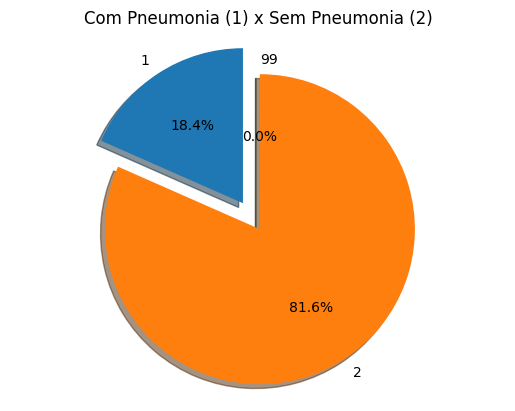

In [29]:
# Obtém a frequência absoluta de pessoas com pneumonia
serie_pneumonia = df_covid.groupby("pneumonia").size()

# coloca "explode" com 0 em todos os índices, exceção o índece 0 com o valor 0.2
explode = tuple(0 if i != 0 else 0.2 for i in range(serie_pneumonia.size))

plt.pie(serie_pneumonia.values, explode=explode, labels=serie_pneumonia.index, 
        autopct='%1.1f%%', shadow=True, startangle=90)
# equal garante que o gráfico seja desenhado como um círculo. 
plt.axis('equal')
plt.title("Com Pneumonia (1) x Sem Pneumonia (2)")

plt.show()

A correlação é o relacionamento entre 2 variáveis. O método mais comum para calcular correlação é o método de Pearson, que assume uma distribuição normal dos dados. Correlação de -1 mostra uma correlação negativa, enquanto uma correlação de +1 mostra uma correlação positiva. Uma correlação igual a 0 mostra que não há relacionamento entre as variáveis.

Alguns algoritmos como regressão linear e regressão logística podem apresentar problemas de performance se houver atributos altamente correlacionados (colineares).

<Axes: >

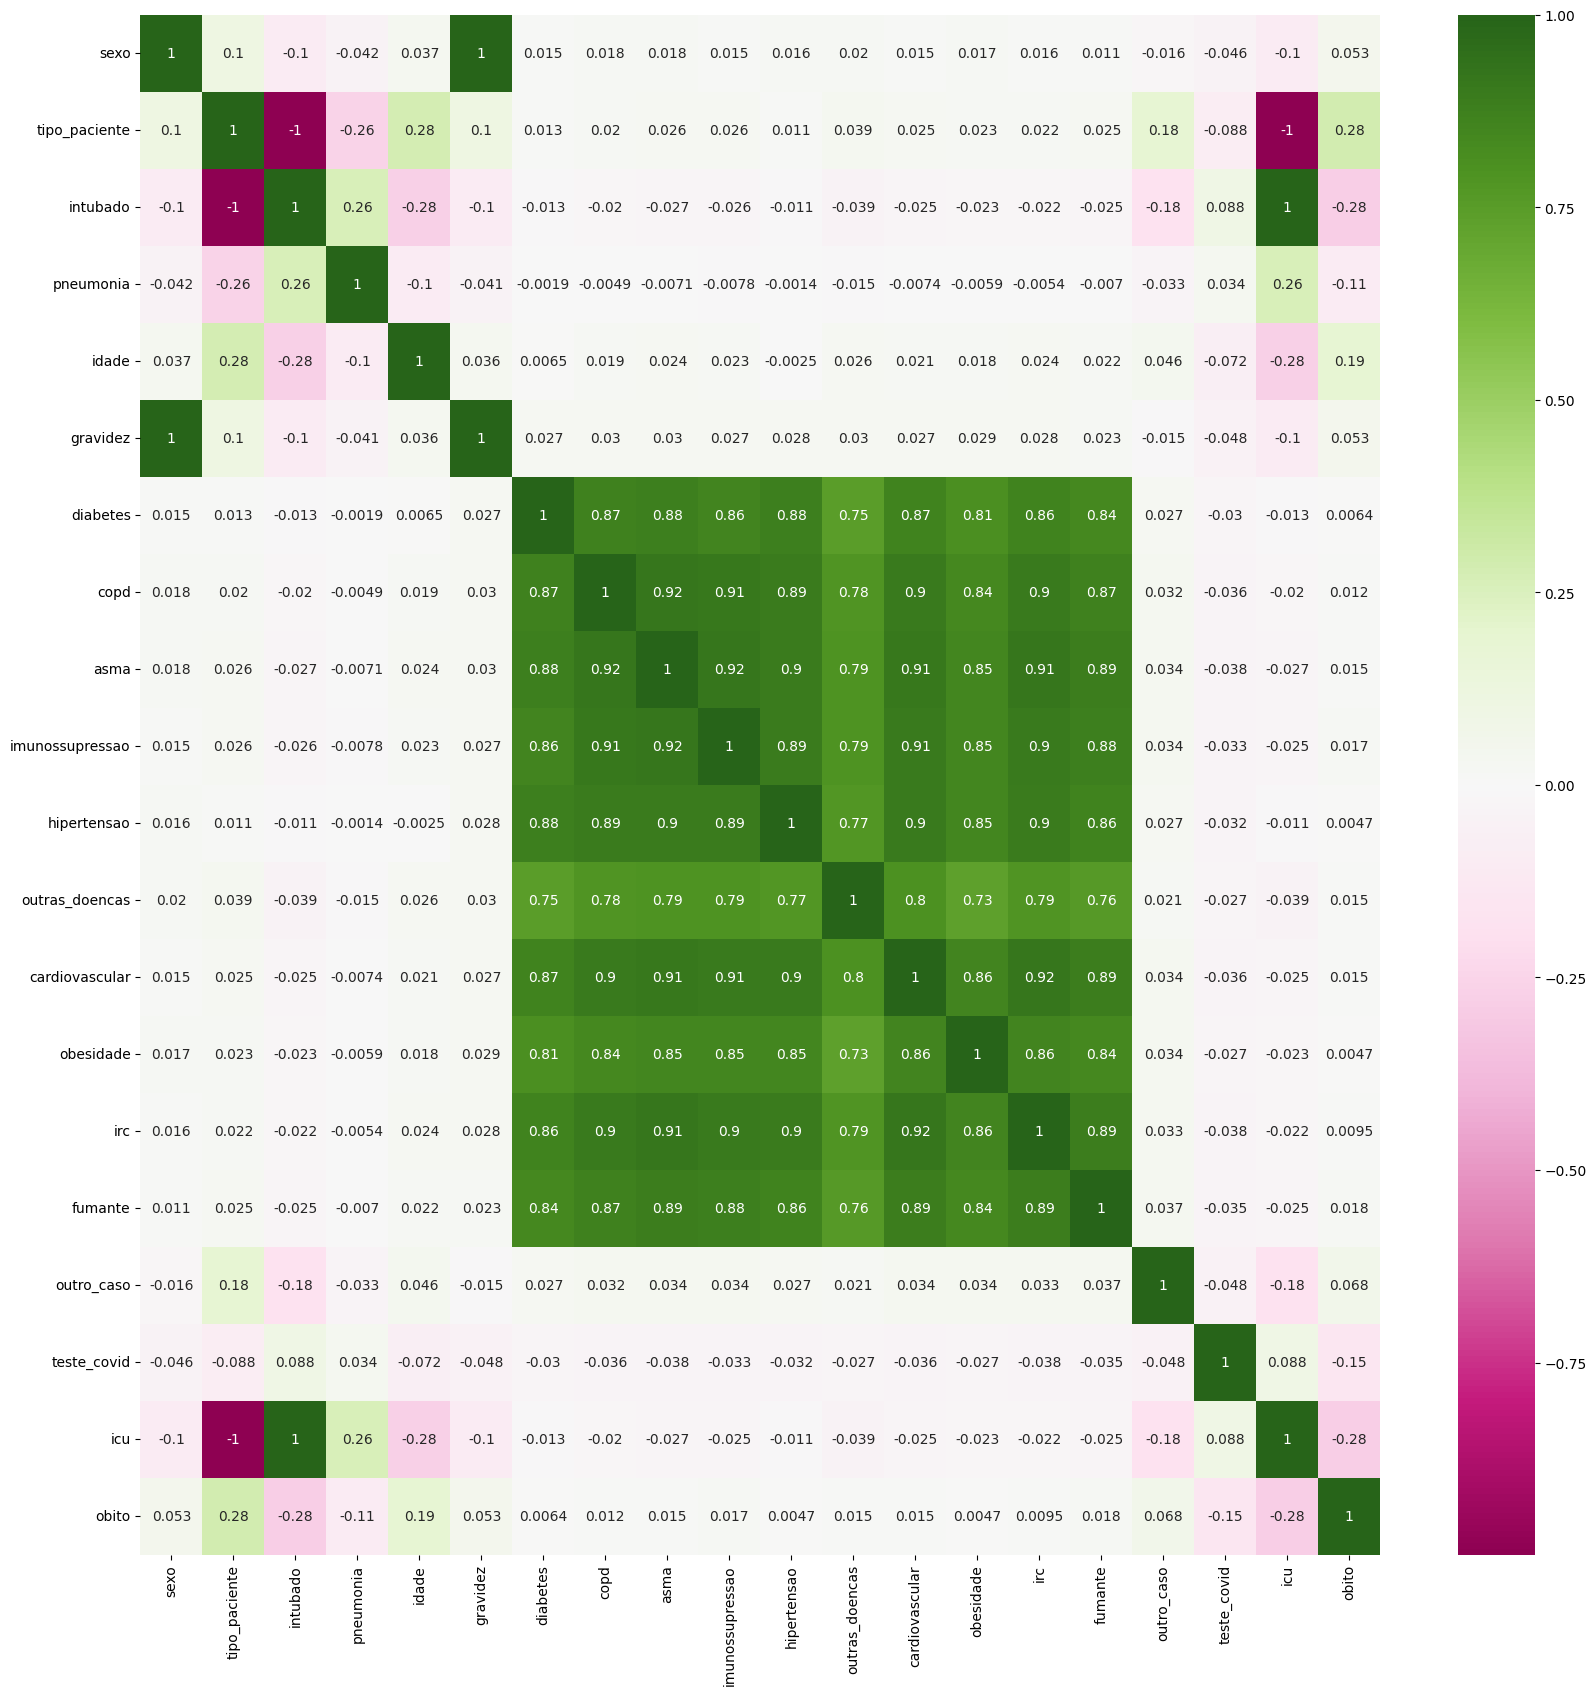

In [30]:
# Cria mapa de calor com a correlação do dataset com o mapa ce cores PiYG
# Aumenta o tamanho da figura a ser exibida
plt.figure(figsize=(20,20))
sns.heatmap(df_covid.corr(), annot=True, cmap = "PiYG")

## Método Ensemble para Seleção de Variáveis

Documentação: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html.
        
Bagged Decision Trees, como o algoritmo RandomForest (são chamados de Métodos Ensemble), podem ser usados para estimar a importância de cada atributo. 

Esse método retorna um score para cada atributo.

Quanto maior o score, maior a importância do atributo.

### Importância do Atributo com o RandomForestClassifier

In [31]:
# Import dos Módulos
from pandas import read_csv
from sklearn.ensemble import RandomForestClassifier

In [32]:
# Reservas feitas antes da seleção de atributos e do treinamento.
from sklearn.model_selection import train_test_split
seed = 7
n_folds = 10
N_JOBS = -1  # Aumente com cautela: o dataset pode ser grande e o SVM é custoso.
df_covid = pd.read_csv('df_covid_preparados.csv', encoding='UTF-8')
if df_covid['obito'].isna().any() or not set(df_covid['obito'].unique()).issubset({0, 1}):
    raise ValueError('obito deve conter apenas 0 (sem óbito) e 1 (com óbito).')
if df_covid.groupby('obito').size().min() < 5:
    raise ValueError('São necessários pelo menos cinco casos por classe para a reserva didática.')
indices_validacao = np.concatenate([
    df_covid[df_covid.obito == classe].sample(n=5, random_state=seed).index.to_numpy()
    for classe in [0, 1]
])
df_validacao_original = df_covid.loc[indices_validacao].copy()
df_restante = df_covid.drop(index=indices_validacao).copy()
df_desenvolvimento, df_teste_final = train_test_split(
    df_restante, test_size=0.3, stratify=df_restante['obito'], random_state=seed)
colunas_entrada = [c for c in df_covid.columns if c != 'obito']
print('Desenvolvimento:', len(df_desenvolvimento),
      '| Teste final:', len(df_teste_final), '| Reserva didática:', len(df_validacao_original))

Desenvolvimento: 67080 | Teste final: 28749 | Reserva didática: 10


In [33]:
# Mostra as colunas do dataset
df_covid.columns

Index(['sexo', 'tipo_paciente', 'intubado', 'pneumonia', 'idade', 'gravidez',
       'diabetes', 'copd', 'asma', 'imunossupressao', 'hipertensao',
       'outras_doencas', 'cardiovascular', 'obesidade', 'irc', 'fumante',
       'outro_caso', 'teste_covid', 'icu', 'obito'],
      dtype='object')

In [34]:
qtdeColunas = len(df_covid.columns)

In [35]:
# Carregando os dados
array = df_covid.values

In [36]:
X = df_desenvolvimento[colunas_entrada].to_numpy(dtype=float)
Y = df_desenvolvimento['obito'].to_numpy()

In [37]:
X

array([[ 2.,  2.,  2., ...,  2.,  1.,  2.],
       [ 1.,  1., 97., ...,  1.,  2., 97.],
       [ 1.,  2.,  2., ..., 99.,  1.,  2.],
       ...,
       [ 2.,  2.,  2., ..., 99.,  2.,  2.],
       [ 1.,  1., 97., ...,  1.,  3., 97.],
       [ 1.,  1., 97., ...,  1.,  3., 97.]])

In [38]:
Y

array([0, 0, 0, ..., 0, 0, 0], dtype=int64)

In [39]:
# Importância demonstrativa: ajustada somente no desenvolvimento.
modelo = RandomForestClassifier(n_estimators=100, random_state=seed, n_jobs=1)
modelo.fit(X, Y)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [40]:
sAtributos = pd.Series(modelo.feature_importances_, index=colunas_entrada)

In [41]:
# Mostra a importância dos atributos
# Considerando este fato, podemos selecionar os mais relevantes
# Claro que podemos utilizar o nosso conhecimento sobre o assunto
sAtributos.sort_values(ascending=False)[0:qtdeColunas-1]

idade              0.434899
intubado           0.064649
teste_covid        0.059742
outro_caso         0.053845
icu                0.052942
pneumonia          0.043792
obesidade          0.035421
diabetes           0.030608
hipertensao        0.029876
fumante            0.027070
tipo_paciente      0.023910
cardiovascular     0.022205
outras_doencas     0.021501
copd               0.019723
irc                0.018280
imunossupressao    0.017336
gravidez           0.016506
sexo               0.015621
asma               0.012074
dtype: float64

In [42]:
# Exportação ilustrativa. A avaliação repetirá a seleção dentro de cada fold.
k_atributos = min(10, len(colunas_entrada))
atributos_selecionados = sAtributos.nlargest(k_atributos).index.tolist()
dfcovid_SPAtribSelec = df_restante[atributos_selecionados + ['obito']].copy()
dfcovid_SPAtribSelec.head(3)

,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante,obito
0,42,97,1,99,97,2,2,2,2,2,0
1,51,97,1,99,97,2,2,2,2,2,0
2,51,2,1,99,2,2,1,1,1,2,0


In [43]:
# Salvando os atributos preparados
dfcovid_SPAtribSelec.to_csv("dfcovid_atrib_selec.csv", index=False)

# Reserva didática: dez casos independentes do treinamento
Cinco casos com óbito e cinco sem óbito foram sorteados e removidos da base de modelagem antes da seleção de atributos. Esses casos são distintos dos **dez folds**, que são divisões internas do desenvolvimento.

A amostra de dez casos serve para inspecionar previsões, não para estimar desempenho populacional. O teste final usa 30% da base restante, preservando a proporção de classes.

In [44]:
# Import dos Módulos
from pandas import read_csv

In [45]:
# Exporta a reserva nas mesmas colunas do CSV demonstrativo.
df_validacao = df_validacao_original[atributos_selecionados + ['obito']].copy()
df_validacao.to_csv('dfcovid_atrib_selec_valida.csv', index=False)

In [46]:
# O pipeline usará os atributos originais; a seleção ocorre internamente.
df_validacao = df_validacao_original.copy()

In [47]:
# Apresente o seu conteúdo com df_validacao.head(10)

In [48]:
df_validacao.head(10)

,sexo,tipo_paciente,intubado,pneumonia,idade,gravidez,diabetes,copd,asma,imunossupressao,hipertensao,outras_doencas,cardiovascular,obesidade,irc,fumante,outro_caso,teste_covid,icu,obito
37317,1,1,97,2,47,2,2,2,2,2,2,2,2,2,2,2,2,2,97,0
84125,2,1,97,2,25,97,2,2,2,2,2,2,2,2,2,2,99,2,97,0
84798,1,1,97,2,42,2,2,2,2,2,2,2,2,2,2,2,2,2,97,0
55050,2,1,97,2,42,97,2,2,2,2,2,2,2,2,2,2,99,2,97,0
23057,1,1,97,2,32,2,2,2,2,2,2,2,2,2,2,2,99,2,97,0
62963,2,1,97,1,88,97,2,2,2,2,2,2,2,2,2,2,2,1,97,1
19127,2,2,1,1,57,97,2,1,2,2,2,2,2,2,2,2,2,1,1,1
63168,2,2,1,1,55,97,2,2,2,2,2,2,2,2,2,2,2,1,2,1
19668,2,2,2,1,71,97,2,2,2,2,2,2,2,2,2,1,99,1,2,1
58267,2,2,2,1,52,97,2,2,2,2,2,2,1,2,2,2,99,1,2,1


# Classificação com validação cruzada estratificada — 10 folds
Comparamos KNN, CART, regressão logística, Naive Bayes, SVM, Random Forest e AdaBoost nas mesmas dez divisões de desenvolvimento.

A seleção das dez variáveis mais importantes por Random Forest é ajustada dentro de cada fold usando `SelectFromModel` em um `Pipeline`. A padronização de KNN, LR e SVM também é interna ao fold. Não usamos o CSV selecionado globalmente na avaliação.

Resultados: acurácia média e desvio-padrão por fold; matrizes e relatórios OOF (cada exemplo previsto quando fora do treinamento). O teste final e os dez casos didáticos não participam da comparação ou da busca.

Dependência: mantenha `df_covid_preparados.csv` na mesma pasta. Se a preparação externa envolver imputação, normalização ou balanceamento aprendidos globalmente, mova-os para o pipeline para evitar vazamento. Assume-se uma linha independente por caso; pacientes repetidos exigem folds por grupo. Preditores devem estar disponíveis no momento pretendido da previsão; atributos posteriores a esse momento devem ser retirados de `colunas_entrada`.

A escolha entre algoritmos ocorre no desenvolvimento. A avaliação final não deve orientar novas escolhas. Documentação: https://scikit-learn.org/stable/modules/cross_validation.html

### Desenvolvimento, validação cruzada e teste final
Após remover os dez casos didáticos, 70% dos exemplos compõem o desenvolvimento e 30% o teste final. Cada rodada usa nove folds do desenvolvimento para treinamento e um para validação.

`StratifiedKFold(n_splits=10, shuffle=True, random_state=7)` mantém aproximadamente as proporções de classes. A avaliação é condicionada à preparação prévia do CSV e não é validação cruzada aninhada.

## Avaliando a Performance


As métricas que você escolhe para avaliar a performance do modelo vão influenciar a forma como a performance é medida e comparada com modelos criados com outros algoritmos.

Vamos utilizar o mesmo algoritmo, mas com métricas diferentes e assim comparar os resultados. 

### Métricas para Algoritmos de Classificação

Documentação: https://scikit-learn.org/stable/modules/model_evaluation.html.

## Como consultar os atributos selecionados

`criar_pipeline()` apenas monta as etapas: os nomes só podem ser obtidos **depois do treinamento (`fit`)**. Neste notebook, `k_atributos = min(10, len(colunas_entrada))` e a seleção usa `SelectFromModel` com Random Forest.

- **Comparação dos sete classificadores:** uma tabela para cada modelo mostra os atributos selecionados nos 10 folds. As tabelas ficam disponíveis em `dicAtributosFolds['KNN']`, por exemplo.
- **Busca de hiperparâmetros:** a tabela mostra a seleção por fold comum aos candidatos, pois a busca modifica somente o classificador. Somente os seletores são reajustados para obter os nomes; os dados de validação não entram nesse ajuste.
- **Modelo final e modelo carregado:** tabelas mostram os atributos do ajuste em todo o desenvolvimento. As previsões posteriores reutilizam essa seleção.

As colunas “Atributo 1”, “Atributo 2”, etc. indicam a ordem de importância **para apresentação**, não a ordem de entrada no classificador. O valor de importância vem do Random Forest usado na seleção, não necessariamente do classificador final. A seleção pode variar entre folds e coincidir entre classificadores: neste exemplo, todos usam o mesmo seletor, dados e semente. As tabelas largas permitem rolagem horizontal.

Execute o notebook desde o início, mantendo `df_covid_preparados.csv` na pasta de execução. As tabelas serão preenchidas com os resultados reais; não são pré-calculadas neste arquivo.


In [49]:
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectFromModel
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier

def criar_pipeline(estimador, padronizar=False):
    etapas = [('selecao', SelectFromModel(
        RandomForestClassifier(n_estimators=100, random_state=seed, n_jobs=1),
        threshold=-np.inf, max_features=k_atributos))]
    if padronizar:
        etapas.append(('escala', StandardScaler()))
    etapas.append(('classificador', estimador))
    return Pipeline(etapas)
# Exibe nomes reais dos atributos após o ajuste; criar_pipeline só monta as etapas.
from IPython.display import display, Markdown
from sklearn.base import clone

def tabela_atributos(pipeline_ajustado, nomes_colunas):
    seletor = pipeline_ajustado.named_steps['selecao']
    indices = seletor.get_support(indices=True)
    importancias = seletor.estimator_.feature_importances_
    quadro = pd.DataFrame({
        'Atributo selecionado': np.asarray(nomes_colunas)[indices],
        'Importância (Random Forest da seleção)': importancias[indices]
    }).sort_values('Importância (Random Forest da seleção)', ascending=False)
    quadro.insert(0, 'Posição por importância', range(1, len(quadro) + 1))
    return quadro.reset_index(drop=True)

def mostrar_atributos(pipeline_ajustado, nomes_colunas, titulo):
    quadro = tabela_atributos(pipeline_ajustado, nomes_colunas)
    display(Markdown(f'### {titulo} — {len(quadro)} atributos selecionados'))
    display(quadro.style.hide(axis='index').format(
        {'Importância (Random Forest da seleção)': '{:.4f}'}))
    return quadro

def mostrar_atributos_folds(pipelines_ajustados, nomes_colunas, titulo):
    registros = []
    for fold, pipeline in enumerate(pipelines_ajustados, 1):
        nomes = tabela_atributos(pipeline, nomes_colunas)['Atributo selecionado'].tolist()
        registros.append({'Fold': fold, 'Quantidade': len(nomes),
                          **{f'Atributo {j}': nome for j, nome in enumerate(nomes, 1)}})
    quadro = pd.DataFrame(registros)
    display(Markdown(f'### {titulo}: atributos por fold'))
    display(Markdown('Os atributos aparecem em ordem decrescente de importância. '
                     'Essa ordem é apenas de exibição; o pipeline preserva a ordem das colunas.'))
    display(quadro.style.hide(axis='index').set_properties(**{
        'white-space': 'normal', 'text-align': 'left', 'font-size': '12px'
    }).set_table_attributes('style="display:block;overflow-x:auto;max-width:100%"'))
    return quadro


In [50]:
# Reutiliza o desenvolvimento original, com todos os atributos candidatos.
df_covid = df_desenvolvimento.copy()

In [51]:
array = df_covid.values

In [52]:
df_covid.shape

(67080, 20)

In [53]:
qtdeColunas = len(df_covid.columns)

In [54]:
X = df_covid[colunas_entrada].to_numpy(dtype=float)
Y = df_covid['obito'].to_numpy()
if not np.isfinite(X).all():
    raise ValueError('Há valores ausentes ou infinitos: prepare os dados dentro do pipeline.')

In [55]:
X

array([[ 2.,  2.,  2., ...,  2.,  1.,  2.],
       [ 1.,  1., 97., ...,  1.,  2., 97.],
       [ 1.,  2.,  2., ..., 99.,  1.,  2.],
       ...,
       [ 2.,  2.,  2., ..., 99.,  2.,  2.],
       [ 1.,  1., 97., ...,  1.,  3., 97.],
       [ 1.,  1., 97., ...,  1.,  3., 97.]])

In [56]:
Y

array([0, 0, 0, ..., 0, 0, 0], dtype=int64)

In [57]:
seed = 7
n_folds = 10

In [58]:
X_treino, Y_treino = X, Y
X_teste = df_teste_final[colunas_entrada].to_numpy(dtype=float)
Y_teste = df_teste_final['obito'].to_numpy()
if pd.Series(Y_treino).value_counts().min() < n_folds:
    raise ValueError('Cada classe precisa ter pelo menos dez casos no desenvolvimento.')
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)
folds = list(cv.split(X_treino, Y_treino))
pd.DataFrame([{'fold': i, 'n_treino': len(tr), 'n_validacao': len(va)}
              for i, (tr, va) in enumerate(folds, 1)])

,fold,n_treino,n_validacao
0,1,60372,6708
1,2,60372,6708
2,3,60372,6708
3,4,60372,6708
4,5,60372,6708
5,6,60372,6708
6,7,60372,6708
7,8,60372,6708
8,9,60372,6708
9,10,60372,6708


In [59]:
modelos = [
    ('KNN', criar_pipeline(KNeighborsClassifier(), True)),
    ('CART', criar_pipeline(DecisionTreeClassifier(random_state=seed))),
    ('LR', criar_pipeline(LogisticRegression(max_iter=2000, random_state=seed), True)),
    ('NB', criar_pipeline(GaussianNB())),
    ('SVM', criar_pipeline(SVC(), True)),
    ('RFor', criar_pipeline(RandomForestClassifier(random_state=seed))),
    ('AdaB', criar_pipeline(AdaBoostClassifier(random_state=seed)))
]

In [60]:
dicAtributosFolds = {}
dicAcuracia, dicDesvio, dicMatriz, dicRelatorio, dicScores = {}, {}, {}, {}, {}
for nome, modelo in modelos:
    print('Avaliando:', nome)
    resultados = cross_validate(modelo, X_treino, Y_treino, cv=folds,
                                scoring='accuracy', n_jobs=N_JOBS, error_score='raise',
                                return_estimator=True)
    scores = resultados['test_score'] * 100
    # Inspeciona os pipelines efetivamente treinados em cada fold.
    dicAtributosFolds[nome] = mostrar_atributos_folds(
        resultados['estimator'], colunas_entrada, nome)
    # Reutiliza esses ajustes para obter previsões fora do treinamento (OOF).
    previsoes = np.empty_like(Y_treino)
    for pipeline_fold, (_, indices_validacao) in zip(resultados['estimator'], folds):
        previsoes[indices_validacao] = pipeline_fold.predict(X_treino[indices_validacao])
    dicScores[nome] = scores
    dicAcuracia[nome] = scores.mean()
    dicDesvio[nome] = scores.std(ddof=1)
    dicMatriz[nome] = confusion_matrix(Y_treino, previsoes, labels=[0, 1])
    dicRelatorio[nome] = classification_report(Y_treino, previsoes, labels=[0, 1],
        target_names=['sem óbito', 'com óbito'], zero_division=0)
    print(f'{nome}: {scores.mean():.3f}% ± {scores.std(ddof=1):.3f} pontos percentuais')
pdScoresFolds = pd.DataFrame(dicScores, index=range(1, 11))
pdScoresFolds.index.name = 'fold'
display(pdScoresFolds)

Avaliando: KNN


### KNN: atributos por fold

Os atributos aparecem em ordem decrescente de importância. Essa ordem é apenas de exibição; o pipeline preserva a ordem das colunas.

Fold,Quantidade,Atributo 1,Atributo 2,Atributo 3,Atributo 4,Atributo 5,Atributo 6,Atributo 7,Atributo 8,Atributo 9,Atributo 10
1,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
2,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
3,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
4,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
5,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
6,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
7,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
8,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
9,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
10,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,hipertensao,diabetes,fumante


KNN: 96.088% ± 0.107 pontos percentuais
Avaliando: CART


### CART: atributos por fold

Os atributos aparecem em ordem decrescente de importância. Essa ordem é apenas de exibição; o pipeline preserva a ordem das colunas.

Fold,Quantidade,Atributo 1,Atributo 2,Atributo 3,Atributo 4,Atributo 5,Atributo 6,Atributo 7,Atributo 8,Atributo 9,Atributo 10
1,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
2,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
3,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
4,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
5,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
6,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
7,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
8,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
9,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
10,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,hipertensao,diabetes,fumante


CART: 95.400% ± 0.219 pontos percentuais
Avaliando: LR


### LR: atributos por fold

Os atributos aparecem em ordem decrescente de importância. Essa ordem é apenas de exibição; o pipeline preserva a ordem das colunas.

Fold,Quantidade,Atributo 1,Atributo 2,Atributo 3,Atributo 4,Atributo 5,Atributo 6,Atributo 7,Atributo 8,Atributo 9,Atributo 10
1,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
2,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
3,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
4,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
5,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
6,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
7,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
8,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
9,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
10,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,hipertensao,diabetes,fumante


LR: 96.383% ± 0.035 pontos percentuais
Avaliando: NB


### NB: atributos por fold

Os atributos aparecem em ordem decrescente de importância. Essa ordem é apenas de exibição; o pipeline preserva a ordem das colunas.

Fold,Quantidade,Atributo 1,Atributo 2,Atributo 3,Atributo 4,Atributo 5,Atributo 6,Atributo 7,Atributo 8,Atributo 9,Atributo 10
1,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
2,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
3,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
4,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
5,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
6,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
7,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
8,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
9,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
10,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,hipertensao,diabetes,fumante


NB: 90.805% ± 0.583 pontos percentuais
Avaliando: SVM


### SVM: atributos por fold

Os atributos aparecem em ordem decrescente de importância. Essa ordem é apenas de exibição; o pipeline preserva a ordem das colunas.

Fold,Quantidade,Atributo 1,Atributo 2,Atributo 3,Atributo 4,Atributo 5,Atributo 6,Atributo 7,Atributo 8,Atributo 9,Atributo 10
1,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
2,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
3,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
4,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
5,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
6,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
7,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
8,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
9,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
10,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,hipertensao,diabetes,fumante


SVM: 96.418% ± 0.007 pontos percentuais
Avaliando: RFor


### RFor: atributos por fold

Os atributos aparecem em ordem decrescente de importância. Essa ordem é apenas de exibição; o pipeline preserva a ordem das colunas.

Fold,Quantidade,Atributo 1,Atributo 2,Atributo 3,Atributo 4,Atributo 5,Atributo 6,Atributo 7,Atributo 8,Atributo 9,Atributo 10
1,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
2,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
3,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
4,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
5,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
6,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
7,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
8,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
9,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
10,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,hipertensao,diabetes,fumante


RFor: 95.714% ± 0.126 pontos percentuais
Avaliando: AdaB


### AdaB: atributos por fold

Os atributos aparecem em ordem decrescente de importância. Essa ordem é apenas de exibição; o pipeline preserva a ordem das colunas.

Fold,Quantidade,Atributo 1,Atributo 2,Atributo 3,Atributo 4,Atributo 5,Atributo 6,Atributo 7,Atributo 8,Atributo 9,Atributo 10
1,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
2,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
3,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
4,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
5,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
6,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
7,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
8,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
9,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
10,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,hipertensao,diabetes,fumante


AdaB: 96.340% ± 0.141 pontos percentuais


,KNN,CART,LR,NB,SVM,RFor,AdaB
fold,,,,,,,
1,96.034586,95.348837,96.377460,91.040549,96.422182,95.706619,96.243292
2,95.930233,95.617174,96.332737,91.129994,96.407275,95.721527,96.466905
3,96.153846,95.125224,96.377460,91.204532,96.422182,95.721527,96.511628
4,96.079308,95.557543,96.422182,90.205725,96.422182,95.855695,96.451998
5,95.989863,94.946333,96.392367,89.877758,96.422182,95.497913,96.109123
6,95.960048,95.378652,96.317829,91.085271,96.422182,95.542636,96.213476
7,96.124031,95.632081,96.422182,89.997018,96.422182,95.751342,96.466905
8,96.243292,95.393560,96.392367,91.666667,96.422182,95.796064,96.273107
9,96.198569,95.468098,96.392367,91.010733,96.407275,95.900417,96.228384


In [61]:
pdAcuraciaModelos = pd.DataFrame({'nome': list(dicAcuracia), 'acuracia': list(dicAcuracia.values()), 'desvio_padrao': list(dicDesvio.values())})

In [62]:
# Apresenta a acurácia dos modelos ordenados
pdAcuraciaModelos.sort_values(ascending=False, by='acuracia')

,nome,acuracia,desvio_padrao
4,SVM,96.417710,0.007201
2,LR,96.383423,0.034571
6,AdaB,96.340191,0.141120
0,KNN,96.088253,0.106624
5,RFor,95.714073,0.126348
1,CART,95.399523,0.218893
3,NB,90.805009,0.582766


In [63]:
# Relatórios OOF; a lista de modelos não é duplicada.
for nome in dicRelatorio:
    print(nome)
    print(dicRelatorio[nome])

KNN
              precision    recall  f1-score   support

   sem óbito       0.97      0.99      0.98     64679
   com óbito       0.34      0.10      0.15      2401

    accuracy                           0.96     67080
   macro avg       0.65      0.55      0.57     67080
weighted avg       0.94      0.96      0.95     67080

CART
              precision    recall  f1-score   support

   sem óbito       0.97      0.98      0.98     64679
   com óbito       0.28      0.18      0.22      2401

    accuracy                           0.95     67080
   macro avg       0.62      0.58      0.60     67080
weighted avg       0.95      0.95      0.95     67080

LR
              precision    recall  f1-score   support

   sem óbito       0.96      1.00      0.98     64679
   com óbito       0.25      0.01      0.01      2401

    accuracy                           0.96     67080
   macro avg       0.61      0.50      0.50     67080
weighted avg       0.94      0.96      0.95     67080

NB
    

In [64]:
# Apresenta a matriz de confusão para o KNN
dicMatriz['KNN']

array([[64220,   459],
       [ 2165,   236]], dtype=int64)

In [65]:
# Apresenta a matriz de confusão para o CART
dicMatriz['CART']

array([[63562,  1117],
       [ 1969,   432]], dtype=int64)

In [66]:
# Apresenta a matriz de confusão para o Regressão Logística
dicMatriz['LR']

array([[64641,    38],
       [ 2388,    13]], dtype=int64)

In [67]:
# Apresenta a matriz de confusão para o Naive Bayes
dicMatriz['NB']

array([[59435,  5244],
       [  924,  1477]], dtype=int64)

In [68]:
# Apresenta a matriz de confusão para o SVM
dicMatriz['SVM']

array([[64677,     2],
       [ 2401,     0]], dtype=int64)

In [69]:
# Apresenta a matriz de confusão para o Random Forest
dicMatriz['RFor']

array([[63773,   906],
       [ 1969,   432]], dtype=int64)

In [70]:
# Apresenta a matriz de confusão para o Random Forest
dicMatriz['AdaB']

array([[64307,   372],
       [ 2083,   318]], dtype=int64)

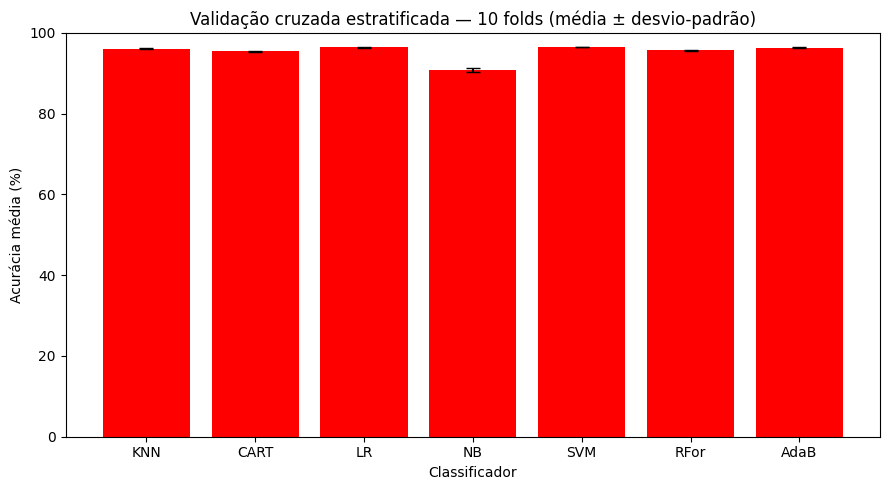

In [71]:
plt.figure(figsize=(9, 5))
plt.bar(list(dicAcuracia), list(dicAcuracia.values()),
        yerr=[dicDesvio[n] for n in dicAcuracia], capsize=5, color='red')
plt.ylabel('Acurácia média (%)')
plt.xlabel('Classificador')
plt.title('Validação cruzada estratificada — 10 folds (média ± desvio-padrão)')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

# Otimização do Modelo - Ajuste de Hyperparâmetros
<font color='red' size='4'><b>Escolha um algoritmo para realizar o ajuste de parâmetros</b></font>

Todos os algoritmos de Aprendizado de Máquina são parametrizados, o que significa que você pode ajustar a performance do seu modelo preditivo, através do <i>tuning</i> (ajuste fino) dos parâmetros. 

Seu trabalho é encontrar a melhor combinação entre os parâmetros em cada algoritmo de Aprendizado de Máquina. 

Esse processo também é chamado de Otimização Hyperparâmetro. 

O scikit-learn oferece dois métodos para otimização automática dos parâmetros: <i>Grid Search Parameter Tuning</i> e <i>Random Search Parameter Tuning</i>. 

# RandomizedSearchCV com dez folds
Exemplo executável: ajuste de AdaBoost com 20 configurações (mínimo solicitado na atividade). O grupo pode substituir o estimador e as distribuições, justificando a escolha pela avaliação de desenvolvimento.

Cada configuração utiliza dez folds: 200 ajustes, além do reajuste final. A seleção Random Forest é reaprendida em cada ajuste, aumentando o custo. `best_score_` é usado na seleção e não equivale a uma avaliação independente.

Documentação: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html

In [72]:
# Import dos módulos
import numpy as np

# Uma variável aleatória contínua uniforme.
# No formulário padrão, a distribuição é uniforme em [0, 1]. 
# Usando os parâmetros loc e scale, obtém-se a distribuição uniforme em [loc, loc + scale].
from scipy.stats import uniform

from sklearn.model_selection import RandomizedSearchCV
# Importando o módulo do algoritmo selecionado
from sklearn.ensemble import AdaBoostClassifier

In [73]:
# Mantém a mesma base de desenvolvimento, sem teste ou reserva didática.
df_covid = df_desenvolvimento.copy()

In [74]:
# Obtém os dados
array = df_covid.values

In [75]:
qtdeColunas = len(df_covid.columns)

In [76]:
# Reutiliza X_treino, Y_treino e folds da comparação; não altera as reservas.

In [77]:
X

array([[ 2.,  2.,  2., ...,  2.,  1.,  2.],
       [ 1.,  1., 97., ...,  1.,  2., 97.],
       [ 1.,  2.,  2., ..., 99.,  1.,  2.],
       ...,
       [ 2.,  2.,  2., ..., 99.,  2.,  2.],
       [ 1.,  1., 97., ...,  1.,  3., 97.],
       [ 1.,  1., 97., ...,  1.,  3., 97.]])

In [78]:
Y

array([0, 0, 0, ..., 0, 0, 0], dtype=int64)

In [79]:
# Dois hiperparâmetros do classificador dentro do pipeline.
# learning_rate é amostrado em escala logarítmica.
from scipy.stats import randint, loguniform
valores_grid = {
    'classificador__n_estimators': randint(20, 201),
    'classificador__learning_rate': loguniform(0.01, 2.0)
}
seed = 7

In [80]:
# Exemplo inicial; o grupo pode escolher outro modelo e ajustar valores_grid.
modelo = criar_pipeline(AdaBoostClassifier(random_state=seed))

In [81]:
iterations = 20
rsearch = RandomizedSearchCV(modelo, param_distributions=valores_grid,
                            n_iter=iterations, random_state=seed, cv=folds,
                            scoring='accuracy', n_jobs=N_JOBS,
                            refit=True, error_score='raise')

In [82]:
rsearch.fit(X_treino, Y_treino)

,estimator,Pipeline(step...om_state=7))])
,param_distributions,"{'classificador__learning_rate': <scipy.stats....001D637C17D00>, 'classificador__n_estimators': <scipy.stats....001D62FDED0F0>}"
,n_iter,20
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,"[(array([ 0,...67078, 67079]), ...), (array([ 0,...67078, 67079]), ...), ...]"
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,7
,error_score,'raise'


In [83]:
print('Melhores parâmetros:', rsearch.best_params_)
print(f'Melhor acurácia média de validação: {rsearch.best_score_ * 100:.3f}%')
# Todos os candidatos da busca alteram apenas parâmetros do classificador.
# A seleção é, portanto, igual entre candidatos dentro de um mesmo fold:
# mesmos dados, mesmo Random Forest e mesma seed.
# RandomizedSearchCV não conserva os estimadores de cada fold. Para inspecionar
# essa seleção, reajustamos somente o seletor, sem repetir a busca/classificador.
seletores_busca = []
for indices_treino, _ in folds:
    seletor_fold = clone(rsearch.best_estimator_.named_steps['selecao'])
    seletor_fold.fit(X_treino[indices_treino], Y_treino[indices_treino])
    seletores_busca.append(Pipeline([('selecao', seletor_fold)]))
atributos_busca_folds = mostrar_atributos_folds(
    seletores_busca, colunas_entrada,
    'Busca de hiperparâmetros — seleção comum aos candidatos')
del seletores_busca


Melhores parâmetros: {'classificador__learning_rate': 0.12899176624716355, 'classificador__n_estimators': 192}
Melhor acurácia média de validação: 96.479%


### Busca de hiperparâmetros — seleção comum aos candidatos: atributos por fold

Os atributos aparecem em ordem decrescente de importância. Essa ordem é apenas de exibição; o pipeline preserva a ordem das colunas.

Fold,Quantidade,Atributo 1,Atributo 2,Atributo 3,Atributo 4,Atributo 5,Atributo 6,Atributo 7,Atributo 8,Atributo 9,Atributo 10
1,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
2,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
3,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
4,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
5,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
6,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
7,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
8,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
9,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,diabetes,hipertensao,fumante
10,10,idade,intubado,teste_covid,outro_caso,icu,pneumonia,obesidade,hipertensao,diabetes,fumante


In [84]:
# Preserva X_treino/Y_treino e o teste reservado; não relê nem divide novamente a base.

In [85]:
# Preserva X_treino/Y_treino e o teste reservado; não relê nem divide novamente a base.

In [86]:
modelo = rsearch.best_estimator_
atributos_modelo_final = mostrar_atributos(
    modelo, colunas_entrada, 'Modelo otimizado: ajuste em todo o desenvolvimento')


### Modelo otimizado: ajuste em todo o desenvolvimento — 10 atributos selecionados

Posição por importância,Atributo selecionado,Importância (Random Forest da seleção)
1,idade,0.4349
2,intubado,0.0646
3,teste_covid,0.0597
4,outro_caso,0.0538
5,icu,0.0529
6,pneumonia,0.0438
7,obesidade,0.0354
8,diabetes,0.0306
9,hipertensao,0.0299
10,fumante,0.0271


In [87]:
# refit=True já ajustou o pipeline em todo o desenvolvimento.
previsoes = modelo.predict(X_teste)

In [88]:
matrix = confusion_matrix(Y_teste, previsoes, labels=[0, 1])
report = classification_report(Y_teste, previsoes, labels=[0, 1], target_names=['sem óbito', 'com óbito'], zero_division=0)
result = modelo.score(X_teste, Y_teste)

In [89]:
# Imprime os resultados
print("Acurácia nos Dados de Teste: %.3f%%" % (result * 100.0))

# Imprimindo a Matriz de Confusão
print(matrix)

# Imprimindo o relatório
print(report)

Acurácia nos Dados de Teste: 96.522%
[[27669    51]
 [  949    80]]
              precision    recall  f1-score   support

   sem óbito       0.97      1.00      0.98     27720
   com óbito       0.61      0.08      0.14      1029

    accuracy                           0.97     28749
   macro avg       0.79      0.54      0.56     28749
weighted avg       0.95      0.97      0.95     28749



# Salvando o modelo

O modelo deve ser obtido pelo algoritmo utilizado na etapa anterior, otimização do modelo, com os melhores valores para os seus hiperparâmetros.

In [90]:
# Import dos módulos
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

# Importando o módulo do algoritmo selecionado
from sklearn.ensemble import AdaBoostClassifier

# Importando o pacote utilizado para salvar o modelo como arquivo binário
import joblib

In [91]:
# Preserva X_treino/Y_treino e o teste reservado; não relê nem divide novamente a base.

In [92]:
# Preserva X_treino/Y_treino e o teste reservado; não relê nem divide novamente a base.

In [93]:
# Preserva X_treino/Y_treino e o teste reservado; não relê nem divide novamente a base.

In [94]:
# Preserva X_treino/Y_treino e o teste reservado; não relê nem divide novamente a base.

In [95]:
# Preserva X_treino/Y_treino e o teste reservado; não relê nem divide novamente a base.

In [96]:
# Preserva X_treino/Y_treino e o teste reservado; não relê nem divide novamente a base.

In [97]:
# Reutiliza o pipeline otimizado, treinado somente no desenvolvimento.
modelo = rsearch.best_estimator_

In [98]:
# O pipeline já está treinado; nenhuma reserva é incorporada ao ajuste.

In [99]:
arquivo = 'modelo_otimizado_class_obitoCOVID_cv10.sav'
joblib.dump({'pipeline': modelo, 'colunas_entrada': colunas_entrada}, arquivo)
print('Pipeline e ordem de entrada salvos!')

Pipeline e ordem de entrada salvos!


In [100]:
pacote = joblib.load(arquivo)
modelo_class_final = pacote['pipeline']
colunas_modelo = pacote['colunas_entrada']
print('Modelo carregado!')
atributos_modelo_carregado = mostrar_atributos(
    modelo_class_final, colunas_modelo, 'Modelo carregado do arquivo')


Modelo carregado!


### Modelo carregado do arquivo — 10 atributos selecionados

Posição por importância,Atributo selecionado,Importância (Random Forest da seleção)
1,idade,0.4349
2,intubado,0.0646
3,teste_covid,0.0597
4,outro_caso,0.0538
5,icu,0.0529
6,pneumonia,0.0438
7,obesidade,0.0354
8,diabetes,0.0306
9,hipertensao,0.0299
10,fumante,0.0271


In [101]:
# Fazendo previsões
Y_pred = modelo_class_final.predict(X_teste)

In [102]:
# Obtendo a matriz de confusão
matrix = confusion_matrix(Y_teste, Y_pred); matrix

array([[27669,    51],
       [  949,    80]], dtype=int64)

In [103]:
# Score do modelo nos dados de teste  (Acurácia)
result = modelo_class_final.score(X_teste, Y_teste)

In [104]:
# Imprime os resultados
print("Acurácia nos Dados de Teste: %.3f%%" % (result * 100.0))

Acurácia nos Dados de Teste: 96.522%


# Validação didática com dez casos reservados
Esses registros nunca participaram da seleção, dos folds ou da busca. A tabela permite inspecionar acertos e erros individualmente. Como contém apenas dez casos balanceados por construção, não representa a distribuição populacional e não substitui o teste final.

In [105]:
X_validacao = df_validacao_original[colunas_modelo].to_numpy(dtype=float)
Y_validacao = df_validacao_original['obito'].to_numpy()
previsoes_validacao = modelo_class_final.predict(X_validacao)

### Monte um quadro com os resultados obtidos para os 10 dados de validação

In [106]:
quadro_validacao = df_validacao_original.copy()
quadro_validacao['obito_previsto'] = previsoes_validacao
quadro_validacao['acertou'] = (Y_validacao == previsoes_validacao)
quadro_validacao

,sexo,tipo_paciente,intubado,pneumonia,idade,gravidez,diabetes,copd,asma,imunossupressao,...,cardiovascular,obesidade,irc,fumante,outro_caso,teste_covid,icu,obito,obito_previsto,acertou
37317,1,1,97,2,47,2,2,2,2,2,...,2,2,2,2,2,2,97,0,0,True
84125,2,1,97,2,25,97,2,2,2,2,...,2,2,2,2,99,2,97,0,0,True
84798,1,1,97,2,42,2,2,2,2,2,...,2,2,2,2,2,2,97,0,0,True
55050,2,1,97,2,42,97,2,2,2,2,...,2,2,2,2,99,2,97,0,0,True
23057,1,1,97,2,32,2,2,2,2,2,...,2,2,2,2,99,2,97,0,0,True
62963,2,1,97,1,88,97,2,2,2,2,...,2,2,2,2,2,1,97,1,0,False
19127,2,2,1,1,57,97,2,1,2,2,...,2,2,2,2,2,1,1,1,0,False
63168,2,2,1,1,55,97,2,2,2,2,...,2,2,2,2,2,1,2,1,0,False
19668,2,2,2,1,71,97,2,2,2,2,...,2,2,2,1,99,1,2,1,0,False
58267,2,2,2,1,52,97,2,2,2,2,...,1,2,2,2,99,1,2,1,0,False


In [107]:
print(confusion_matrix(Y_validacao, previsoes_validacao, labels=[0, 1]))
print(classification_report(Y_validacao, previsoes_validacao, labels=[0, 1], target_names=['sem óbito', 'com óbito'], zero_division=0))

[[5 0]
 [5 0]]
              precision    recall  f1-score   support

   sem óbito       0.50      1.00      0.67         5
   com óbito       0.00      0.00      0.00         5

    accuracy                           0.50        10
   macro avg       0.25      0.50      0.33        10
weighted avg       0.25      0.50      0.33        10



### <font size = '2'>prof. Dr. Ivan Carlos Alcântara de Oliveira</font> - <font color="blue" size = '2'>https://orcid.org/0000-0002-6020-7535.</font><br><font size = '2'> e-mail: ivan.oliveira@mackenzie.br</font>